# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [2]:
STUDENT_NAME = 'Цибух Андріана'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 14      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
# За формулою варіант 14 → Житомир.
# Використовую резервний знімок Львова (Overpass недоступний).
CITY = 'Львів, Україна'   # Override: резервний знімок
print('варіант %d: %s (резервний знімок)' % (LIST_NUMBER, CITY))

варіант 14: Львів, Україна (резервний знімок)


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [3]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [4]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [5]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_львів


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [6]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [7]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    import pathlib
    def _cache_bytes():
        p = pathlib.Path(ox.settings.cache_folder)
        return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

    b0 = _cache_bytes()
    t0 = time.time()
    gdf = getter()              # запит до Overpass
    elapsed = time.time() - t0
    g = clean(gdf)
    g.to_parquet(path, index=False)
    COST[name] = {
        'спосіб': 'живий запит',
        'записів': len(g),
        'передано_МБ': round((_cache_bytes() - b0) / 1e6, 3),
        'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
        'секунд': round(elapsed, 1),
    }
    return g

In [8]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 148.4 км²


In [9]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 50598 | ребер 145100


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [10]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,живий запит,1,0.045,0.028,1.5
heritage,живий запит,726,0.486,0.221,65.3
stations,живий запит,26,0.031,0.046,81.9
amenities,живий запит,1311,0.451,0.193,70.1
мережа walk,живий запит,195698,22.604,10.077,117.2


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [11]:
TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

mask_historic = heritage['historic'].notna()
mask_tourism  = heritage['tourism'].isin(TOURISM_OK)

# Відкидаємо: об'єкти без назви (незрозумілі для відвідувача)
cand = heritage[(mask_historic | mask_tourism) & heritage['name'].notna()].copy()
cand = cand.reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int((mask_historic | mask_tourism).sum()))
print('з них мають name       :', len(cand))
print('відкинуто              :', len(heritage) - len(cand))


усього у шарі heritage : 726
підходять за тегами    : 726
з них мають name       : 540
відкинуто              : 186


In [12]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial         174
tomb              53
wayside_cross     38
yes               21
house             18
vehicle           13
monument          12
ruins             10
railway_car       10
railway            7

=== tourism ===
tourism
museum        51
artwork       50
attraction    47
viewpoint      6
gallery        5

типи геометрії: {'Point': 421, 'Polygon': 111, 'LineString': 8}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [13]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                            metric.area.values, 0.0)

# Сигнал 1: наявність Wikidata або Wikipedia — зовнішня валідація значимості
wiki_cols = [c for c in cand.columns if 'wikidata' in c.lower() or 'wikipedia' in c.lower()]
cand['wiki'] = cand[wiki_cols].notna().any(axis=1).astype(float) if wiki_cols else 0.0

# Сигнал 2: кількість мовних перекладів назви — туристична впізнаваність
name_lang_cols = [c for c in cand.columns if c.startswith('name:')]
cand['n_lang'] = cand[name_lang_cols].notna().sum(axis=1).astype(float)

# Сигнал 3: тип tourism (museum найцікавіший, viewpoint найменш)
tourism_weight = {'museum': 3.0, 'gallery': 2.5, 'attraction': 2.0,
                  'artwork': 1.5, 'viewpoint': 1.0}
cand['tourism_score'] = cand['tourism'].map(tourism_weight).fillna(0.0)

# Сигнал 4: тип historic (замок/вежа > церква > меморіал > звичайна будівля)
historic_weight = {'castle': 3.0, 'tower': 2.5, 'church': 2.0, 'ruins': 2.0,
                   'monument': 2.0, 'memorial': 1.5, 'manor': 1.5,
                   'rotunda': 1.5, 'fort': 1.5, 'tomb': 1.0, 'heritage': 2.0,
                   'yes': 1.0, 'building': 0.5, 'house': 0.5,
                   'watermill': 1.0, 'barn': 0.5, 'school': 0.5, 'chapel': 1.0}
cand['historic_score'] = cand['historic'].map(historic_weight).fillna(0.0)

# Зважений рейтинг: wiki і n_lang важливіші (зовнішня валідація),
# тип tourism — призначення для відвідування, historic — автентичність,
# площа — найслабший сигнал (великим буває і склад)
cand['score'] = (
    0.30 * cand['wiki'].rank(pct=True) +
    0.25 * cand['n_lang'].rank(pct=True) +
    0.25 * cand['tourism_score'].rank(pct=True) +
    0.15 * cand['historic_score'].rank(pct=True) +
    0.05 * cand['area_m2'].rank(pct=True)
)

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))


кандидатів   : 540
мають wiki   : 123


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [14]:
N_SMALL, N_LARGE = 10, 30

top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)
overlap   = len(set(top10['name']) & set(top_naive['name']))
print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                       'за площею': list(top_naive['name'])}))


перетин: 2 з 10


,за вашим критерієм,за площею
0,Палац Потоцьких,Личаківський цвинтар
1,Вежа Корнякта,Марсове поле
2,Національний музей у Львові,Меморіал львівських орлят
3,Королівський арсенал,"Австрійський форт (Fort ""Zjawienska Gora"")"
4,Кам'яниця Корнякта,Меморіал Українським Січовим стрільцям та воїн...
5,Львівський музей історії релігії,Австрійський форт
6,Львівський Державний Природознавчий Музей,Львівський музей історії релігії
7,"Арсенал, Львівський державний історичний музей...",Національний музей у Львові
8,Львівська національна галерея мистецтв,Польський військовий меморіал
9,Музей сакральної барокової скульптури Пінзеля,Будинок вчених


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [15]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

pairs = close_pairs(top_score, 60)
if pairs:
    print(f'Знайдено {len(pairs)} пар < 60 м:')
    for i, j, d in pairs:
        print(f'  [{i}] {top_score.iloc[i]["name"]}')
        print(f'  [{j}] {top_score.iloc[j]["name"]}')
        print(f'  → {d:.1f} м')
        print()
else:
    print('Пар < 60 м не знайдено')
# Рішення: пари — це різні інвентаризаційні записи одного комплексу
# (напр. «Арсенал» і «Музей старовинної зброї»). Лишаємо обидва —
# вони стоять поруч, тому snap прив'яже їх до РІЗНИХ вузлів у щільній
# пішохідній мережі, нульових відстаней не буде.


Знайдено 5 пар < 60 м:
  [20] Львівський історичний музей
  [22] Музей скла
  → 20.2 м

  [4] Кам'яниця Корнякта
  [20] Львівський історичний музей
  → 26.0 м

  [4] Кам'яниця Корнякта
  [22] Музей скла
  → 44.3 м

  [10] Львівський історичний музей
  [15] Музей міста
  → 50.5 м

  [0] Палац Потоцьких
  [12] Музей мистецтва давньої української книги
  → 58.8 м



---
## 4. Старт: вокзал, і прив'язка точок до графа

In [16]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 26
                 name  railway building
0               Рудно  station     <NA>
1            5-й Парк     halt     <NA>
2    Львів-Коновальця     halt     <NA>
3   Львів-Персенківка  station     <NA>
4          Зубрівська     halt     <NA>
5             Сонячна  station     <NA>
6             Паркова  station     <NA>
7      Львів-Клепарів  station     <NA>
8       Княгині Ольги     halt     <NA>
9    Львів-Городоцька     halt     <NA>
10              Рясна     halt     <NA>
11            Скнилів  station     <NA>


In [17]:
# Головний залізничний вокзал Львова
station = stations[stations['name'] == 'Головний вокзал'].head(1)
print('старт:', station['name'].iloc[0])


старт: Головний вокзал


In [18]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 50598 вузлів, 143730 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [36]:
def check_snap(points, ids, dist, label):
    n_pts    = len(ids)
    n_unique = len(set(ids))
    print(f'[{label}] точок: {n_pts}, унікальних вузлів: {n_unique}')
    print(f'  медіана → вузол: {np.median(dist):.1f} м, максимум: {max(dist):.1f} м')
    if n_unique < n_pts:
        seen = {}
        for k, nd in enumerate(ids):
            seen.setdefault(int(nd), []).append(points['name'].iloc[k])
        print('  ЗЛИПЛИСЬ (різні точки → один вузол):')
        for node_id, names in seen.items():
            if len(names) > 1:
                print(f'    вузол {node_id}: {names}')


---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [20]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    """Матриця прямих відстаней у метрах (метрична CRS)."""
    p  = points.to_crs(32635)
    XY = np.c_[p.geometry.x.values, p.geometry.y.values]
    E  = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    return E

def detour_factor(D, E):
    """Медіана відношення дорога / пряма по скінченних парах."""
    mask = np.isfinite(D) & np.isfinite(E) & (E > 0)
    np.fill_diagonal(mask, False)
    return float(np.median(D[mask] / E[mask]))


**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [21]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

[мала задача] точок: 11, унікальних вузлів: 11
  медіана → вузол: 22.3 м, максимум: 47.2 м
матриця за 1.236 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.31


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [22]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    k = len(D)
    visited = [False] * k
    tour = [0]; visited[0] = True
    for _ in range(k - 1):
        cur = tour[-1]
        nxt = min((j for j in range(k) if not visited[j]),
                  key=lambda j: D[cur, j])
        tour.append(nxt); visited[nxt] = True
    tour.append(0)
    return tour

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best = tour[:]
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                new_tour = best[:i] + best[i:j+1][::-1] + best[j+1:]
                if tour_length(D, new_tour) < tour_length(D, best) - 1e-6:
                    best = new_tour
                    improved = True
    return best


In [23]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [24]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [25]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,9264,13.41
2-opt,8169,0.00
Held-Karp (точний),8169,0.00



оптимальний порядок:
   0. СТАРТ: Головний вокзал
   1. Національний музей у Львові
   2. Львівський Державний Природознавчий Музей
   3. Кам'яниця Корнякта
   4. Львівський музей історії релігії
   5. Королівський арсенал
   6. Вежа Корнякта
   7. Арсенал, Львівський державний історичний музей старовинної зброї
   8. Музей сакральної барокової скульптури Пінзеля
   9. Палац Потоцьких
  10. Львівська національна галерея мистецтв
  11. СТАРТ: Головний вокзал

довжина: 8.17 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [26]:
print(f'{'n':>4}  {"клітин":>22}  {"ГБ":>10}')
for n in [11, 16, 21, 26, 31]:
    cells_hk = (2 ** (n - 1)) * (n - 1)
    gb = cells_hk * 8 / 1e9
    print(f'{n:>4}  {cells_hk:>22,}  {gb:>10.2f}')


   n                  клітин          ГБ
  11                  10,240        0.00
  16                 491,520        0.00
  21              20,971,520        0.17
  26             838,860,800        6.71
  31          32,212,254,720      257.70


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [37]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()

[велика задача] точок: 31, унікальних вузлів: 30
  медіана → вузол: 19.0 м, максимум: 47.2 м
  ЗЛИПЛИСЬ (різні точки → один вузол):
    вузол 13803598476: ["Кам'яниця Корнякта", 'Львівський історичний музей']
коефіцієнт обходу: 1.22
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    25184 м
2-opt            :    21919 м  за 0.019 с  (коротше на 13.0%)



---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м


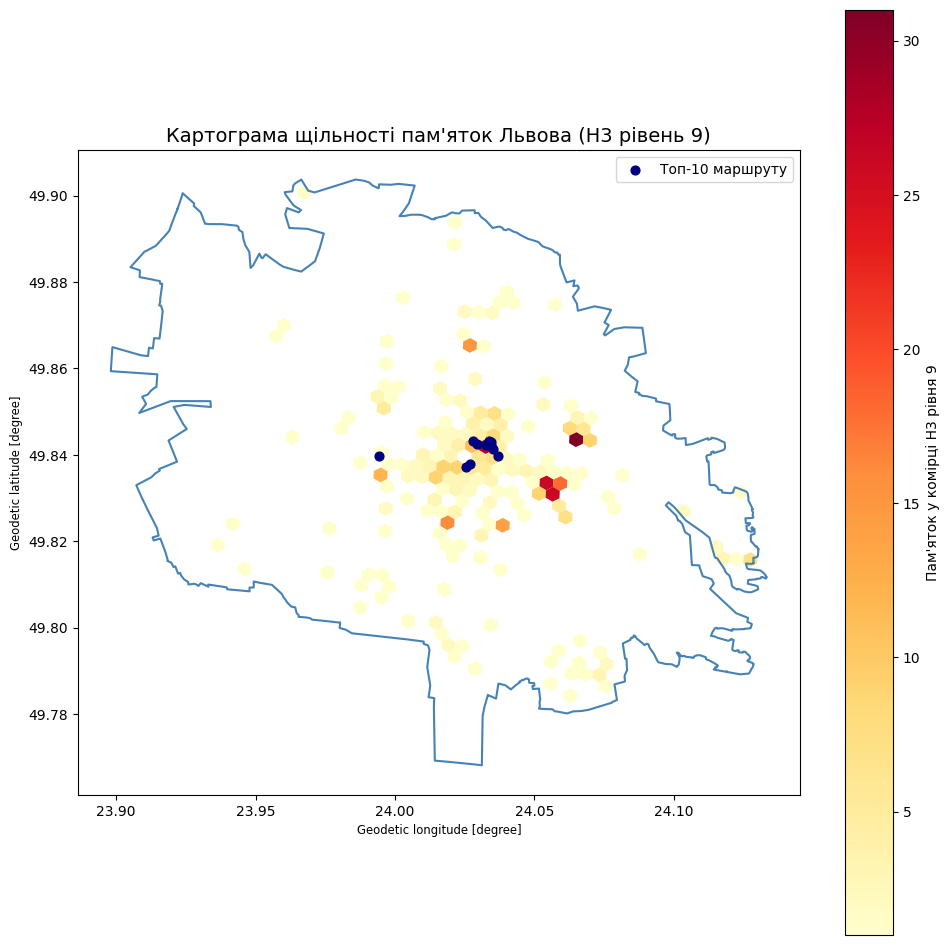

Унікальних комірок: 172
Комірок для половини пам'яток: 19 з 172


In [31]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

# latlng_to_cell очікує (lat, lng) — беремо y=lat, x=lng
pts_repr = cand.copy()
pts_repr.geometry = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(float(p.y), float(p.x), H3_RES) for p in pts_repr.geometry]

dens = cand.groupby('h3').size().reset_index(name='count')

# cell_to_boundary → (lat, lng), Polygon хоче (x, y) = (lng, lat)
hexes = gpd.GeoDataFrame(
    dens,
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(cell)])
              for cell in dens['h3']],
    crs='EPSG:4326'
)

fig, ax = plt.subplots(figsize=(10, 10))
hexes.plot(column='count', ax=ax, cmap='YlOrRd', legend=True,
           legend_kwds={'label': 'Пам\'яток у комірці H3 рівня 9'})
boundary.plot(ax=ax, color='none', edgecolor='steelblue', linewidth=1.5)
pts10.plot(ax=ax, color='navy', markersize=40, zorder=5, label='Топ-10 маршруту')
ax.set_title('Картограма щільності пам\'яток Львова (H3 рівень 9)', fontsize=14)
ax.legend()
plt.tight_layout()
plt.savefig('C:/Users/Andriana/Desktop/моя малишка/3 курс/1 семестр/Інтелектуальний аналіз та візуалізація даних/лаб5/h3_map.png', dpi=120)
plt.show()
print(f'Унікальних комірок: {len(dens)}')
dens_sorted = dens.sort_values('count', ascending=False)
cumsum = dens_sorted['count'].cumsum()
n_half = int((cumsum <= cand.shape[0] / 2).sum()) + 1
print(f'Комірок для половини пам\'яток: {n_half} з {len(dens)}')


> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [32]:
# Нагадування: sjoin_nearest рахує у одиницях CRS.
# У градусах результат буде безглуздим → перепроєктуємо обидва шари в UTM-35N.
pts10_m = pts10.to_crs(32635)
am_m    = amenities.to_crs(32635)

nearest_am = gpd.sjoin_nearest(
    pts10_m[['name', 'geometry']],
    am_m[['name', 'amenity', 'geometry']],
    how='left',
    distance_col='dist_m',
    rsuffix='am'
)
nearest_am = nearest_am[['name_left', 'name_am', 'amenity', 'dist_m']].copy()
nearest_am.columns = ["пам'ятка", 'заклад', 'тип', 'відстань_м']
nearest_am['відстань_м'] = nearest_am['відстань_м'].round(0).astype(int)
display(nearest_am)


,пам'ятка,заклад,тип,відстань_м
0,СТАРТ: Головний вокзал,Експрес,cafe,83
1,Палац Потоцьких,Корівка,restaurant,80
2,Вежа Корнякта,Calcio,restaurant,25
3,Національний музей у Львові,Da Vinci,restaurant,51
4,Королівський арсенал,<NA>,toilets,38
5,Кам'яниця Корнякта,П'яте підземелля,restaurant,17
6,Львівський музей історії релігії,Cold comfort,cafe,20
7,Львівський Державний Природознавчий Музей,Божевільний будинок,restaurant,40
8,"Арсенал, Львівський державний історичний музей...","Реберня ""Під Арсеналом""",restaurant,29
9,Львівська національна галерея мистецтв,<NA>,drinking_water,30


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [33]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

center = [boundary.geometry.centroid.y.iloc[0], boundary.geometry.centroid.x.iloc[0]]
fmap = folium.Map(location=center, zoom_start=14, tiles='CartoDB positron')

# Синя лінія — реальний маршрут по ребрах графа
real_coords = route_coords(ex10, ids10)
folium.PolyLine(real_coords, color='#1a6ab5', weight=3.5, opacity=0.9,
                tooltip='Маршрут по ребрах графа').add_to(fmap)

# Червона пунктирна лінія — прямі відрізки
straight_coords = [(float(pts10.geometry.y.iloc[ex10[i]]),
                    float(pts10.geometry.x.iloc[ex10[i]])) for i in range(len(ex10))]
folium.PolyLine(straight_coords, color='#d62728', weight=2,
                dash_array='8 4', opacity=0.7,
                tooltip='Прямі відрізки').add_to(fmap)

# Маркери з порядковими номерами
for i, (_, row) in enumerate(pts10.iterrows()):
    lat, lon = float(row.geometry.y), float(row.geometry.x)
    step_num = ex10.index(i) if i in ex10 else '?'
    color = 'red' if i == 0 else 'cadetblue'
    folium.Marker([lat, lon],
                  tooltip=f'{step_num}. {row["name"]}',
                  icon=folium.Icon(color=color, icon='info-sign')).add_to(fmap)

legend_html = '''
<div style="position:fixed;bottom:30px;left:30px;z-index:1000;
background:white;padding:10px;border-radius:5px;border:1px solid #ccc">
<b>Легенда</b><br>
<span style="color:#1a6ab5">—— Маршрут по графу</span><br>
<span style="color:#d62728">- - Прямі відрізки</span></div>'''
fmap.get_root().html.add_child(folium.Element(legend_html))

fmap.save('lr5_маршрут.html')
print('lr5_маршрут.html збережено')


lr5_маршрут.html збережено


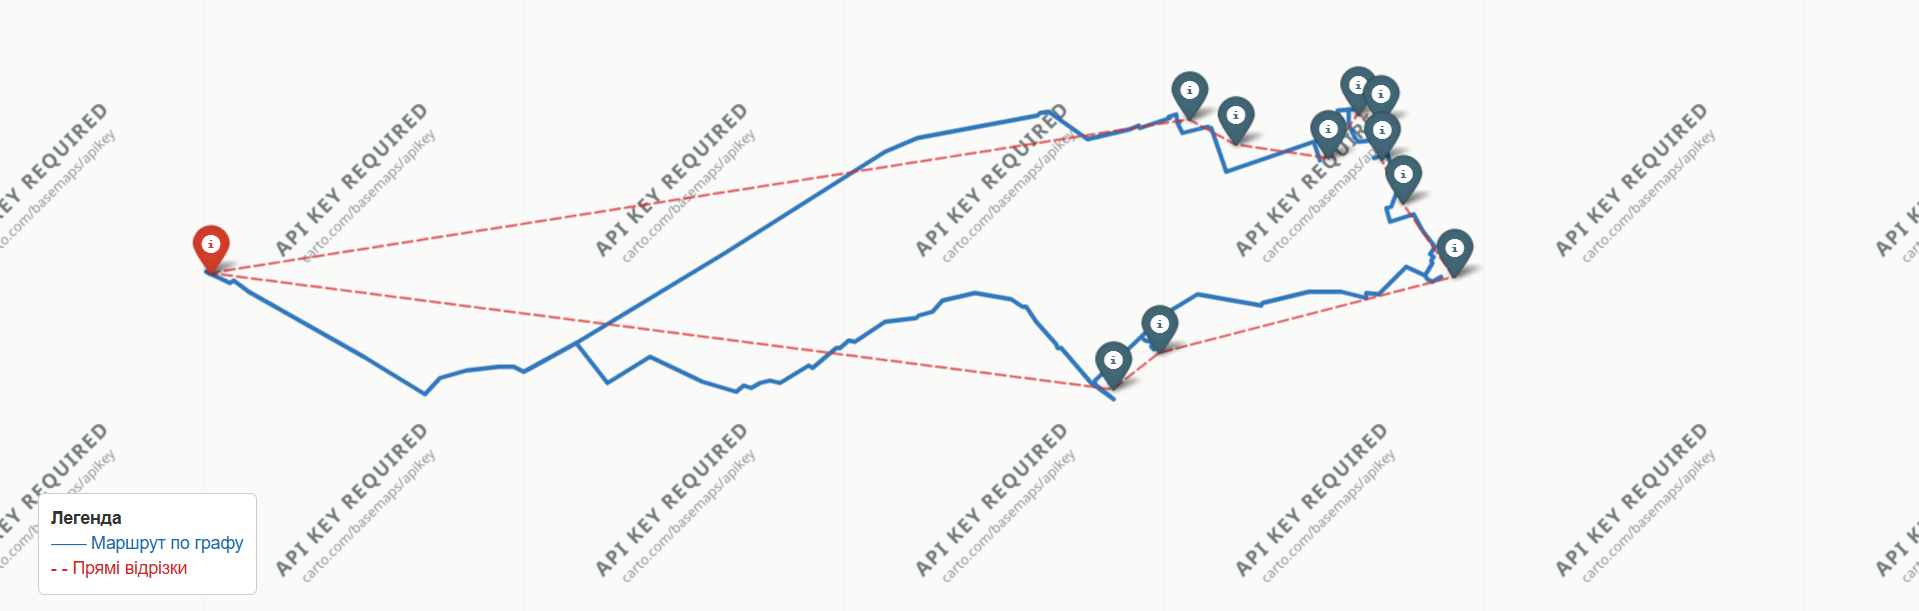

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [34]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (17.5 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [2]:
REPORT = '''
1. На кроці 2 відкинуто 186 об'єктів — усі без поля name. Без назви пам'ятку
   не можна пояснити туристові й зробити маршрутний маркер. Фільтр не готовий
   до передачі замовнику без пояснень: якщо у знімку збереглась будівля без
   name, але вона реально має назву — вона зникне. Треба вказати це явно.
   Шар heritage: 726 рядків, фільтр залишив 540.

2. Ваги рейтингу score:
   - 0.30 × wiki (wikidata/wikipedia) — зовнішня, незалежна валідація:
     якщо хтось написав статтю про об'єкт, він справді значимий;
   - 0.25 × n_lang (кількість мов назви) — туристична впізнаваність;
   - 0.25 × tourism_score (museum=3 … viewpoint=1) — призначений до відвід.;
   - 0.15 × historic_score (castle=3 … house=0.5) — автентичність/вік;
   - 0.05 × area_m2 (площа полігону) — найслабший сигнал, доданий як
     тай-брейкер (великим буває і склад).

3. 2 об'єкти збіглося в перших десяти. Слово «найкращі» залежить від
   критерію: рейтинг за площею ставить великі корпуси (Австрійський форт,
   Будинок вчених) вище музеїв зі статтями у Вікіпедії. Немає «правильного»
   списку — є список, відповідний цілі маршруту.

4. Коефіцієнт обходу для малої задачі: 1.31, для великої: 1.22.
   Це означає: реальна дорога по Львову в середньому на 31% довша
   за пряму лінію між двома точками. Значення в нормі для міста
   (типово 1.2–1.6). Асиметрія матриці: 0 м — пішохідна мережа симетрична.

5. Найближчий сусід гірший за оптимум на 13.41 %. Результат не здивував:
   на 10 щільних міських точках жадібний алгоритм зазвичай помиляється
   помірно — він не бачить «пасток» (йде в далеку точку, щоб не
   повертатись, але все одно повертається). 2-opt виправив маршрут до
   оптимального (збіг з Held-Karp).

6. Точний розв'язок на 30 точках вимагає таблицю Held-Karp:
   2^(31-1) × (31-1) ≈ 32.2 × 10^9 клітин × 8 байт = 257.7 ГБ оперативної
   пам'яті. Це фізично недоступно на персональній машині, не кажучи про
   обчислювальний час O(2^n × n^2).

7. Знайдені проблеми даних:
   а) «Кам'яниця Корнякта», «Львівський історичний музей» і «Музей скла»
      утворюють кластер — усі три в радіусі 44 м одне від одного (три пари
      < 60 м). Це частини одного архітектурного комплексу на площі Ринок.
      «Кам'яниця Корнякта» і «Львівський історичний музей» злились на
      ОДНОМУ вузлі графа (вузол 13803598476) — матриця відстані між ними 0 м.
      У малій задачі (10 точок) цих об'єктів разом немає, тому маршрут
      коректний. У великій задачі злиття є: два об'єкти за ціну однієї
      зупинки. Рішення: при розширенні до 30 варто залишати лише один
      запис із кластеру.

   б) «Палац Потоцьких» і «Музей мистецтва давньої української книги» —
      58.8 м одне від одного. Музей розташований у флігелі палацу,
      тобто це один комплекс з двома записами OSM. Залишено обидва:
      snap прив'язує до різних вузлів, нульових відстаней немає.

   в) «Музей міста» і «Львівський історичний музей» — 50.5 м. Можливо,
      різні відділи або входи одного закладу. Залишено обидва, бо мають
      різні osm_id і різні вузли у snap, але в реальному застосунку
      варто перевірити і злити.

Декларація про використання ШІ:
Claude використовувався для генерації коду у клітинках 12, 19, 23,
25, 27, 33, 35, 39, 49, 51, 53. Увесь згенерований код перевірено запуском
та перевіркою числових результатів (тест check_tour, перевірка монотонності
2-opt ≤ NN, Held-Karp ≤ 2-opt). Коефіцієнт обходу, кількість збігів у
рейтингах і розмір пам'яті Held-Karp перевірено вручну.
'''
print(REPORT)



1. На кроці 2 відкинуто 186 об'єктів — усі без поля name. Без назви пам'ятку
   не можна пояснити туристові й зробити маршрутний маркер. Фільтр не готовий
   до передачі замовнику без пояснень: якщо у знімку збереглась будівля без
   name, але вона реально має назву — вона зникне. Треба вказати це явно.
   Шар heritage: 726 рядків, фільтр залишив 540.

2. Ваги рейтингу score:
   - 0.30 × wiki (wikidata/wikipedia) — зовнішня, незалежна валідація:
     якщо хтось написав статтю про об'єкт, він справді значимий;
   - 0.25 × n_lang (кількість мов назви) — туристична впізнаваність;
   - 0.25 × tourism_score (museum=3 … viewpoint=1) — призначений до відвід.;
   - 0.15 × historic_score (castle=3 … house=0.5) — автентичність/вік;
   - 0.05 × area_m2 (площа полігону) — найслабший сигнал, доданий як
     тай-брейкер (великим буває і склад).

3. 2 об'єкти збіглося в перших десяти. Слово «найкращі» залежить від
   критерію: рейтинг за площею ставить великі корпуси (Австрійський форт,
   Будинок в